# Gold-news sentiment 01: data, splits and gates (no model)

Updated by prompt 01b (2026-11-19): truncated-year dates recovered from the article URL,
two dedupe sets (classifier set and index set), G2 against the MT5 D1 export or Yahoo `GC=F`.

Registration draft: `docs/sentiment/PREREG_SENTIMENT.md` (§2 data, §3 gates; **not approved**).
This notebook runs the data steps in order and shows their tables and plots. All logic lives in
`app/research/sentiment/data.py` and `gates.py` (tested in `tests/test_sentiment_data.py`); the
notebook only calls them. The same results come from the command line:

```
python -m app research sentiment data
python -m app research sentiment gates
```

Rules followed here: no model is trained, scored or loaded; no statistic joins a headline (or
its label) with a price or a volatility; **no headline text is printed** (licence CC BY-NC-ND
4.0; `gates.md` quotes four, the limit is five); the price reader stops before the lockbox
start (2026-01-10).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from app.research.sentiment import data as sd
from app.research.sentiment import gates as sg

pd.set_option("display.width", 120)
cfg = sd.load_config()
print(
    f"config {cfg.path.name}: near Jaccard {cfg.near_jaccard}, window {cfg.window_days} days, "
    f"min test {cfg.min_test}, prices from {cfg.price_first} to before {cfg.price_stop}"
)

config sentiment.toml: near Jaccard 0.8, window 3 days, min test 1500, prices from 2003-01-01 to before 2026-01-10


## Step 0: check the raw files

Every raw file must match the SHA-256 recorded in `app/config/sentiment.toml`; a mismatch stops
the run, so every figure below comes from exactly these bytes. The G2 cross-check files are
optional: the FxPro MT5 D1 export (`mt5`, not received yet) and Yahoo `GC=F` (`gcf`, downloaded
once by `sentiment download`, its SHA-256 recorded then).

In [2]:
status = sd.verify_files(cfg)
pd.DataFrame(
    [
        {"file": k, "status": status[k], "sha256": f.sha256[:16] + "..." if f.sha256 else "-"}
        for k, f in cfg.files.items()
    ]
)

,file,status,sha256
0,gold_zip,ok,eb78715777d15bee...
1,gold,ok,1c2d032de29c0080...
2,fpb_zip,ok,0e1a06c4900fdae4...
3,fpb,ok,5fb370b3005b9a27...
4,dukascopy,ok,2e3567e8f6c7b3e1...
5,mt5,missing,-
6,gcf,ok,216ddc0ff86b42df...


## Step 2: load the gold headlines and recover truncated dates

Columns are mapped to tidy names; the training label is the dataset's Price Sentiment with
`none -> neutral` and an `is_none` flag (PREREG §2.2). Dates are `DD-MM-YYYY`. As evidence on the
date column we count days above 12 (so the order is day-month) and compare with the date many
article URLs carry. Rows with a truncated year (raw `0201-04-27`) take the URL's date when its
month and day equal the raw value's (PREREG §2.1, `sd.recover_date`); the others are dropped.

In [3]:
gold, unparsable = sd.load_gold(cfg.files["gold"].path)
checks = sd.date_checks(gold, unparsable)
n_bad, n_rec = len(unparsable), int(unparsable["recovered"].sum())
print(
    f"rows in file {len(gold) + n_bad - n_rec:,}; not DD-MM-YYYY {n_bad}: recovered {n_rec}, "
    f"dropped {n_bad - n_rec}; dated {len(gold):,}"
)
print(f"date range {gold['date'].min().date()} to {gold['date'].max().date()}")
pd.Series({k: v for k, v in checks.items() if k != "recovered_per_year"}, name="value").to_frame()

rows in file 10,570; not DD-MM-YYYY 165: recovered 160, dropped 5; dated 10,565
date range 2000-02-15 to 2019-02-01


,value
day_field_gt12,6275
url_date_rows,5400
url_date_equal,5338
unparsable_shapes,{'9999-99-99': 165}
unparsable_url_date,161
unparsable_url_mmdd_match,160
recovered,160
recovered_year_prefix_consistent,160
date_dropped,5


,positive,negative,neutral,none
all dated,41.8%,36.1%,3.6%,18.6%


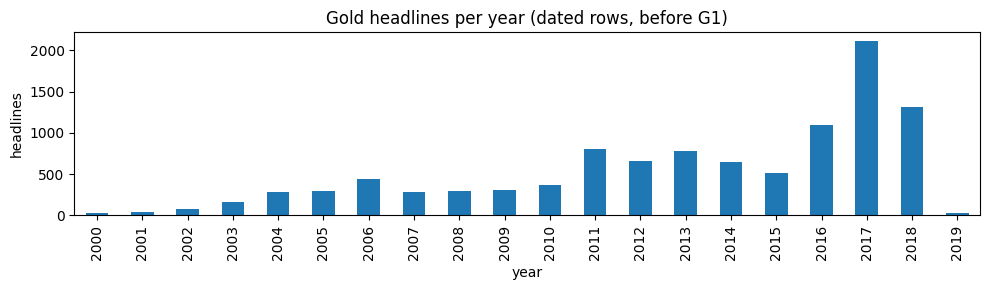

In [4]:
shares = pd.DataFrame({"all dated": sg.label_shares(gold)}).T.map(sg.pct)
display(shares)
per_year = gold.groupby(gold["date"].dt.year).size()
ax = per_year.plot.bar(figsize=(10, 3), title="Gold headlines per year (dated rows, before G1)")
ax.set_xlabel("year")
ax.set_ylabel("headlines")
plt.tight_layout()
plt.show()

## Step 3: G1 deduplicate (before any split), two sets

Normalised text = lower case, every run of punctuation, digits or other non-letters becomes a
space, spaces collapsed. Rows are taken in date order and the earliest is kept.

- **Classifier set** (train / validation / test of the classifier): exact duplicates of that
  text are dropped at any distance in time; then a headline whose token set has Jaccard >= 0.8
  with a kept headline at most 3 days earlier is dropped. Deduplicating before the split keeps
  repeated wire headlines and price-report templates from sitting in both train and test
  (PREREG §10.4).
- **Index set** (the daily index, PREREG §5): exact and near duplicates are dropped only within
  3 days of a kept headline (the same story on several sites); a template headline on another
  day is that day's news and stays.

In [5]:
gold = sd.dedupe(gold, cfg.near_jaccard, cfg.window_days)
display(sg.g1_table(gold, "classifier").set_index("year").T)
sg.g1_table(gold, "index").set_index("year").T

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,all
rows,30,36,76,168,287,299,444,289,297,310,...,804,661,784,643,520,1100,2111,1316,26,10565
exact removed,0,0,0,11,41,60,70,23,49,42,...,43,38,45,39,44,150,302,103,1,1098
near removed,0,0,0,0,0,4,2,0,4,0,...,7,1,2,1,3,9,17,8,0,58
kept,30,36,76,157,246,235,372,266,244,268,...,754,622,737,603,473,941,1792,1205,25,9409


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,all
rows,30,36,76,168,287,299,444,289,297,310,...,804,661,784,643,520,1100,2111,1316,26,10565
exact removed,0,0,0,0,8,10,8,4,10,7,...,4,1,3,0,2,17,39,2,0,117
near removed,0,0,0,0,5,6,8,2,9,0,...,10,1,2,1,4,10,30,8,0,96
kept,30,36,76,168,274,283,428,283,278,303,...,790,659,779,642,514,1073,2042,1306,26,10352


Because digits are stripped and exact matching is global (no date window), recurring
price-report templates collapse across years. The table shows how far each exact duplicate is from
the headline it repeats, and how often its Price Sentiment differs (the kept one is used).

In [6]:
sg.g1_exact_table(gold)

,gap,n,label differs
0,same day,8,0
1,1-3 days,21,0
2,4-30 days,185,3
3,over 30 days,884,21
4,all,1098,24


## Step 4: split by date (PREREG §2.5)

Default: train <= 2012, validation 2013-2015, test 2016+. If the default test split held fewer
than 1,500 classifier-set headlines the code would switch to 2011 / 2012-2014 / 2015+; the choice
is made from the count alone, before any model. Then we check that no normalised text of the
classifier set is in two splits.

In [7]:
kept_mask = gold["in_classifier_set"]
choice = sd.choose_split(
    gold.loc[kept_mask, "date"], cfg.default_split, cfg.fallback_split, cfg.min_test
)
gold["split"] = sd.assign_split(gold["date"], choice.train_last, choice.val_last)
sd.assert_disjoint(gold.loc[kept_mask, "norm"], gold.loc[kept_mask, "split"])
print(
    f"chosen: {choice.name} (train <= {choice.train_last}, validation <= {choice.val_last}); "
    f"default test count {choice.test_count_default:,} vs minimum {cfg.min_test:,}"
)
n_index_test = int((gold["in_index_set"] & gold["split"].eq("test")).sum())
print(f"index set in the test years: {n_index_test:,}")
pd.Series(choice.counts, name="classifier set").to_frame()

chosen: default (train <= 2012-12-31, validation <= 2015-12-31); default test count 3,963 vs minimum 1,500
index set in the test years: 4,447


,classifier set
train,3633
validation,1813
test,3963


## Step 5: prices (Dukascopy XAUUSD D1 bid)

Bars start at 00:00 UTC. The reader stops at the first bar on or after 2026-01-10 (the lockbox).
Each short Sunday-evening bar is merged into Monday (open = Sunday open, high/low = max/min,
close = Monday close, volume = sum). 2000-2002 are dropped from the prices (rounded prices,
impossible OHLC) but kept in the trading calendar used to align those years' headlines. Then
OHLC sanity is checked again and the Garman-Klass variance is added. These plots show prices
only; nothing here touches the headlines.

,value
sunday_bars,1173
sunday_merged,1173
sunday_dropped,0
saturday_bars,0
bars_raw,7918
bars_from_first,5988
first_price_day,2003-01-02
last_price_day,2026-01-09
ohlc_violations,0
gk_nonpositive,0


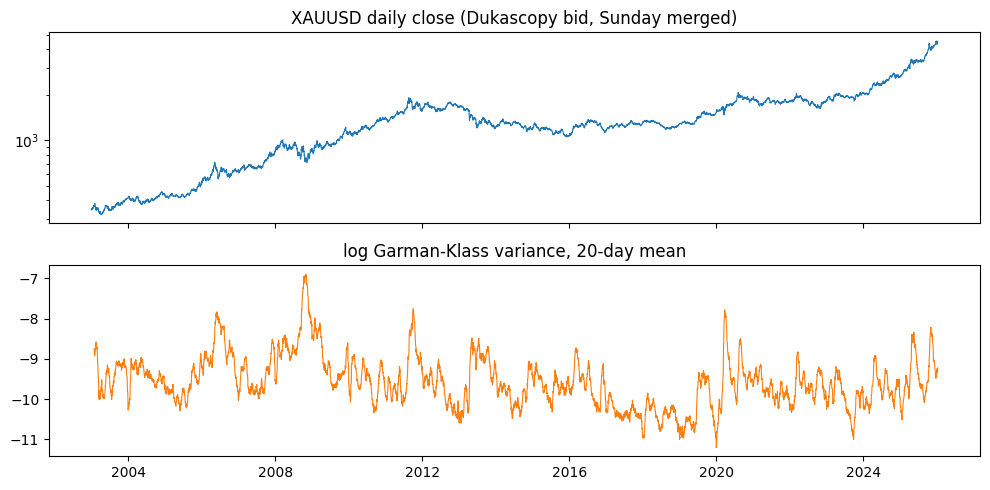

In [8]:
calendar, prices, price_stats, violations = sd.build_prices(cfg)
display(pd.Series(price_stats, name="value").to_frame())
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(prices["date"], prices["close"], lw=0.8)
axes[0].set_yscale("log")
axes[0].set_title("XAUUSD daily close (Dukascopy bid, Sunday merged)")
axes[1].plot(prices["date"], prices["log_gk"].rolling(20).mean(), lw=0.8, color="tab:orange")
axes[1].set_title("log Garman-Klass variance, 20-day mean")
plt.tight_layout()
plt.show()

## G3: align headline dates to price days

A headline dated on a weekend or a weekday without a bar moves to the next price day
(`trade_date`). Only the calendar (which dates have a bar) is used, never a price.

In [9]:
gold["trade_date"] = sd.align_trade_dates(gold["date"], calendar)
gold["moved"] = gold["trade_date"].ne(gold["date"])
kept = gold.loc[gold["in_classifier_set"]]
sg.g3_table(kept)

,year,headlines,weekend,"weekday, no bar",moved
0,2000,30,1,0,1
1,2001,36,0,0,0
2,2002,76,2,0,2
3,2003,157,2,0,2
4,2004,246,0,0,0
5,2005,235,1,0,1
6,2006,372,10,0,10
7,2007,266,5,0,5
8,2008,244,11,0,11
9,2009,268,17,0,17


## G4: label balance and class weights

Class shares per split; the class weights for the weighted cross-entropy come from train only:
w_c = n / (K * n_c).

In [10]:
display(sg.g4_table(kept))
weights = sg.class_weights(kept.loc[kept["split"] == "train", "label"])
pd.Series(weights, name="weight (train only)").to_frame()

,split,headlines,negative,neutral,positive,of which none,first,last
0,train,3633,34.8%,19.5%,45.6%,16.8%,2000-02-15,2012-12-31
1,validation,1813,37.9%,25.7%,36.4%,22.0%,2013-01-02,2015-12-31
2,test,3963,34.2%,27.0%,38.8%,22.7%,2016-01-01,2019-02-01


,weight (train only)
negative,0.956556
neutral,1.708039
positive,0.730398


## G5: coverage

Price days from 2003 (to the last headline's trade date) with no headline, per year, for the
classifier set and the index set on the same price days. Counts only.

,year,price days,"zero, classifier set","share, classifier","zero, index set","share, index"
0,2003,260,143,55.0%,136,52.3%
1,2004,262,106,40.5%,98,37.4%
2,2005,260,116,44.6%,106,40.8%
3,2006,260,72,27.7%,61,23.5%
4,2007,261,83,31.8%,78,29.9%
5,2008,262,101,38.5%,89,34.0%
6,2009,261,93,35.6%,79,30.3%
7,2010,261,85,32.6%,76,29.1%
8,2011,260,38,14.6%,35,13.5%
9,2012,261,32,12.3%,30,11.5%


zero-headline share 2016-2018: {'classifier': '3.1%', 'index': '2.7%'}


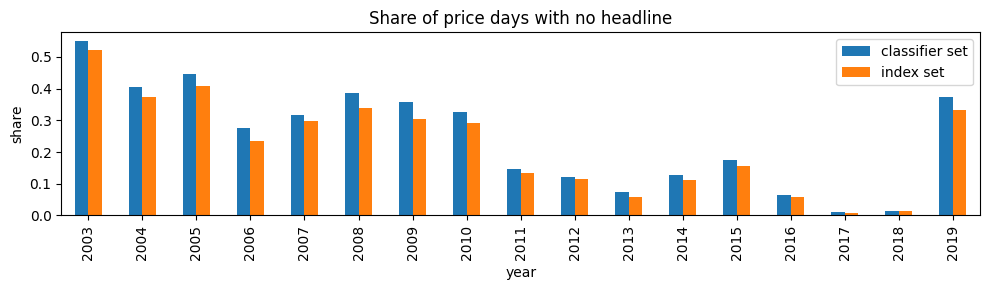

In [11]:
g5, g5_shares = sg.g5_both(gold, calendar, cfg.price_first)
display(g5)
print("zero-headline share 2016-2018:", {k: sg.pct(v) for k, v in g5_shares.items()})
y = g5.set_index("year")
share = pd.DataFrame(
    {
        "classifier set": y["zero, classifier set"] / y["price days"],
        "index set": y["zero, index set"] / y["price days"],
    }
)
ax = share.plot.bar(figsize=(10, 3), title="Share of price days with no headline")
ax.set_ylabel("share")
plt.tight_layout()
plt.show()

## G2: price cross-check

Dukascopy against an independent daily series on common dates from 2003 to 2026-01-09, aligned
by date only (PREREG §2.3 order): the FxPro MT5 D1 export if present (pass: close correlation
>= 0.99), otherwise Yahoo `GC=F` gold futures (pass: log-return correlation >= 0.95; futures
differ by carry and close at another hour). Yahoo bars are dated by the exchange's day, not
00:00 UTC. The investigation (per-year and multi-day return correlations, lead / lag, stale
flat bars) is descriptive and leaves the rule unchanged.

source: gcf | status: fail | rule: return_corr >= 0.95


,G2
common_days,5784
first,2003-01-02
last,2026-01-09
close_corr,0.999936
return_corr,0.882564
share_flagged,0.194363
flagged_count,1124
rule,return_corr
rule_min,0.95
status,fail


return correlation by horizon (common dates): {1: 0.8826, 2: 0.946, 5: 0.9774, 10: 0.989}
Dukascopy t vs other t+1: 0.119; other t vs Dukascopy t+1: -0.014; flat bars 495


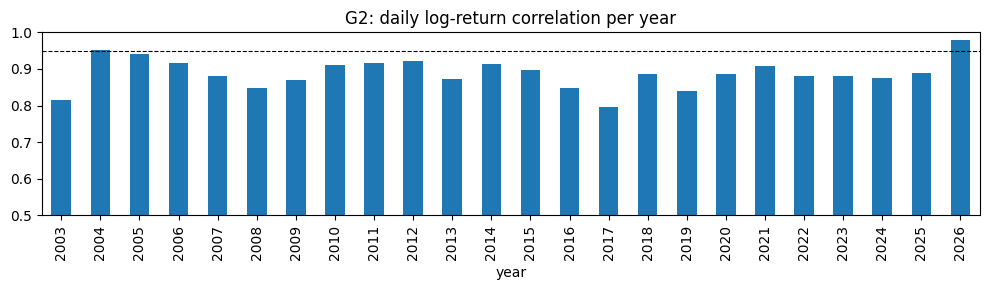

In [12]:
source, other = sg.g2_source(cfg, status)
rule, rule_min = sg.g2_rule(cfg, source)
g2 = sg.g2_crosscheck(
    prices, other, cfg.price_first, rule, rule_min, cfg.g2_return_diff, cfg.g2_list
)
print("source:", source, "| status:", g2["status"], f"| rule: {rule} >= {rule_min}")
display(pd.Series({k: v for k, v in g2.items() if k != "flagged_first"}, name="G2").to_frame())
diag = sg.g2_diagnostics(prices, other, cfg.price_first)
if diag:
    print(
        "return correlation by horizon (common dates):",
        {k: round(v, 4) for k, v in diag["horizons"].items()},
    )
    print(
        f"Dukascopy t vs other t+1: {diag['duka_leads']:.3f}; "
        f"other t vs Dukascopy t+1: {diag['other_leads']:.3f}; flat bars {diag.get('flat')}"
    )
    ax = (
        diag["per_year"]
        .astype({"return corr": float})
        .plot.bar(
            x="year",
            y="return corr",
            figsize=(10, 3),
            legend=False,
            title="G2: daily log-return correlation per year",
        )
    )
    ax.axhline(rule_min, color="black", lw=0.8, ls="--")
    ax.set_ylim(0.5, 1.0)
    plt.tight_layout()
    plt.show()

## FinancialPhraseBank (Sentences_AllAgree)

Used only for stage-1 training (S3); its labels are from an equity investor's point of view.

In [13]:
fpb = sd.load_fpb(cfg.files["fpb"].path)
print(f"rows {len(fpb):,}")
fpb["label"].value_counts(normalize=True).reindex(sd.LABELS).map(sg.pct).to_frame("share")

rows 2,264


,share
label,
negative,13.4%
neutral,61.4%
positive,25.2%


## Reproducibility check

The command-line pipeline (`sd.build`) must give the same headline frame as the steps above, the
saved parquet files must equal it, and `docs/sentiment/gates.md` must equal the report rendered
from the saved files. Only booleans are printed.

In [14]:
built = sd.build(cfg)
cols = [
    "row_id",
    "date",
    "date_recovered",
    "in_classifier_set",
    "in_index_set",
    "dup_exact",
    "dup_near",
    "dup_of",
    "idx_dup_exact",
    "idx_dup_near",
    "split",
    "trade_date",
]


def same(a, b):
    """Column by column (DataFrame.equals also compares pandas' internal block layout)."""
    return all(a[k].equals(b[k]) for k in cols)


same_steps = same(built.gold, gold)
processed = sd.load_processed(cfg)
same_saved = same(processed["gold"], built.gold)
report = sg.render(sg.summarise(processed, cfg, source, other), cfg)
same_report = report == cfg.report.read_text(encoding="utf-8")
print("notebook steps == build():", same_steps)
print("saved parquet == build():", same_saved)
print("gates.md == rendered from saved files:", same_report)
assert same_steps and same_saved and same_report

notebook steps == build(): True
saved parquet == build(): True
gates.md == rendered from saved files: True
